# Clusstering Techniques

## 1. Import libraries and load the dataset

In [11]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import cdist

df = pd.read_csv("Iris.csv")
print(df.head())
print("Dataset shape:", df.shape)

   Id  SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm      Species
0   1            5.1           3.5            1.4           0.2  Iris-setosa
1   2            4.9           3.0            1.4           0.2  Iris-setosa
2   3            4.7           3.2            1.3           0.2  Iris-setosa
3   4            4.6           3.1            1.5           0.2  Iris-setosa
4   5            5.0           3.6            1.4           0.2  Iris-setosa
Dataset shape: (150, 6)


## 2. Select features and scale the data



In [12]:
features = ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm"]

X = df[features]

scaler = StandardScaler()

X = scaler.fit_transform(X)

## 3. Elbow Method


C:\Users\ADARSH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ADARSH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ADARSH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\ADARSH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Wi

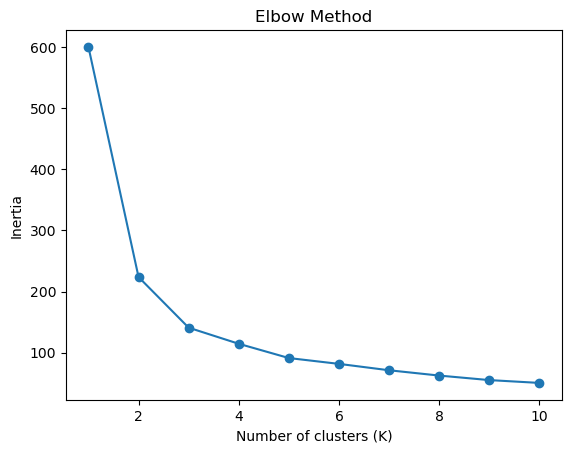

In [13]:
inertia = []
for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X)
    inertia.append(model.inertia_)

plt.plot(range(1, 11), inertia, marker="o")
plt.xlabel("Number of clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method")
plt.show()

**Observation:** For the Iris dataset, K = 3 is a reasonable choice. The elbow may not be perfectly sharp.

## 4. K-Means Clustering

C:\Users\ADARSH\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


K-Means cluster sizes:
KMeans
0    53
1    50
2    47
Name: count, dtype: int64


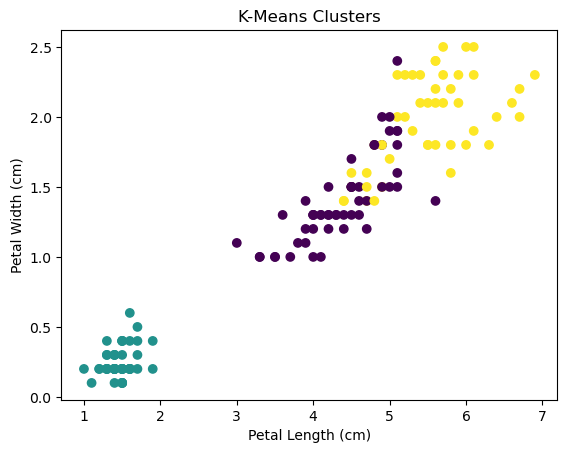

In [25]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
df["KMeans"] = kmeans.fit_predict(X)
print("K-Means cluster sizes:")
print(df["KMeans"].value_counts())

plt.scatter(df["PetalLengthCm"], df["PetalWidthCm"], c=df["KMeans"], cmap="viridis")
plt.xlabel("Petal Length (cm)")
plt.ylabel("Petal Width (cm)")
plt.title("K-Means Clusters")
plt.show()

## 5. Hierarchical Clustering and Dendrogram

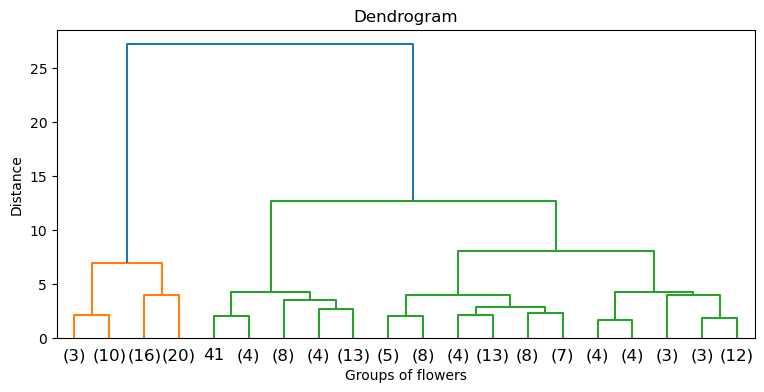

Hierarchical cluster sizes:
Hierarchical
0    71
1    49
2    30
Name: count, dtype: int64


In [15]:
plt.figure(figsize=(9, 4))
dendrogram(linkage(X, method="ward"), truncate_mode="lastp", p=20)
plt.title("Dendrogram")
plt.xlabel("Groups of flowers")
plt.ylabel("Distance")
plt.show()

hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
df["Hierarchical"] = hc.fit_predict(X)
print("Hierarchical cluster sizes:")
print(df["Hierarchical"].value_counts().sort_index())

## 6. Analyze the clusters

In [24]:
# Average measurements of each cluster
print(df.groupby("KMeans")[features].mean().round(2))
print(df.groupby("Hierarchical")[features].mean().round(2))

print("-" *35)

# Compare K-Means with actual species
print(pd.crosstab(df["Species"], df["KMeans"]))
print("-" *35)
print(pd.crosstab(df["Species"], df["Hierarchical"]))
print("-" *35)
print(pd.crosstab(df["KMeans"], df["Hierarchical"]))

        SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
KMeans                                                          
0                5.80          2.67           4.37          1.41
1                5.01          3.42           1.46          0.24
2                6.78          3.10           5.51          1.97
              SepalLengthCm  SepalWidthCm  PetalLengthCm  PetalWidthCm
Hierarchical                                                          
0                      6.55          2.99           5.27          1.85
1                      5.02          3.44           1.47          0.24
2                      5.53          2.57           3.93          1.21
-----------------------------------
KMeans            0   1   2
Species                    
Iris-setosa       0  50   0
Iris-versicolor  39   0  11
Iris-virginica   14   0  36
-----------------------------------
Hierarchical      0   1   2
Species                    
Iris-setosa       0  49   1
Iris-versicolor  23   0 

In [17]:
def dunn_index(X, labels):
    clusters = [X[labels == i] for i in sorted(set(labels))]
    within = max(cdist(c, c).max() for c in clusters)
    between = min(cdist(a, b).min()
                  for i, a in enumerate(clusters)
                  for b in clusters[i + 1:])
    return between / within

print("K-Means:", dunn_index(X, df["KMeans"]))
print("Hierarchical:", dunn_index(X, df["Hierarchical"]))

K-Means: 0.026372443980832196
Hierarchical: 0.09799833591531322


## Result

K-Means and Hierarchical Clustering were implemented using the Iris flower measurements. The Elbow Method and Dendrogram were used to help choose **3 clusters**. Cluster sizes, average feature values and species distribution were compared. Cluster numbers are arbitrary and are not the same as species names.